In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

oil = pd.read_excel("C:/Users/ALIENWARE/OneDrive/Desktop/26s2/ECMT3150/group project/Crude Oil Prices-Brent.xlsx", header=2)

print(oil.head())
print(oil.shape)
print(oil.columns)

  observation_date  OIL$-BRENT
0       2016-01-04       36.28
1       2016-01-05       35.56
2       2016-01-06       33.89
3       2016-01-07       33.57
4       2016-01-08       31.67
(2608, 2)
Index(['observation_date', 'OIL$-BRENT'], dtype='str')


In [21]:
# Rename variables
oil = oil.rename(columns={
    "observation_date": "Date",
    "OIL$-BRENT": "Brent_Price"
})

In [22]:
print(oil.head())

         Date  Brent_Price
0  2016-01-04        36.28
1  2016-01-05        35.56
2  2016-01-06        33.89
3  2016-01-07        33.57
4  2016-01-08        31.67


In [23]:
# Clean Date & Price
oil["Date"] = pd.to_datetime(
    oil["Date"],
    errors="coerce"
)

oil["Brent_Price"] = pd.to_numeric(
    oil["Brent_Price"],
    errors="coerce"
)

oil = oil.sort_values("Date").reset_index(drop=True)

print(oil.dtypes)
print(oil.head())

Date           datetime64[us]
Brent_Price           float64
dtype: object
        Date  Brent_Price
0 2016-01-04        36.28
1 2016-01-05        35.56
2 2016-01-06        33.89
3 2016-01-07        33.57
4 2016-01-08        31.67


In [24]:
# Missing values
print(oil.isna().sum())

# Duplicate dates
print("Duplicates:", oil["Date"].duplicated().sum())

# Date range
print("Start:", oil["Date"].min())
print("End:", oil["Date"].max())

# Descriptive statistics
print(oil["Brent_Price"].describe())

Date            0
Brent_Price    70
dtype: int64
Duplicates: 0
Start: 2016-01-04 00:00:00
End: 2025-12-31 00:00:00
count    2538.000000
mean       67.847561
std        18.896041
min         9.120000
25%        54.692500
50%        68.390000
75%        79.387500
max       133.180000
Name: Brent_Price, dtype: float64


In [25]:
oil = oil.dropna(subset=["Date"])

oil = oil.drop_duplicates(
    subset=["Date"],
    keep="first"
)

oil.loc[
    oil["Brent_Price"] <= 0,
    "Brent_Price"
] = np.nan

No missing values

In [26]:
# Calculate Daily Log Returns
oil["Oil_Return"] = 100 * np.log(
    oil["Brent_Price"] /
    oil["Brent_Price"].shift(1)
)

print(oil[[
    "Date",
    "Brent_Price",
    "Oil_Return"
]].head(10))

        Date  Brent_Price  Oil_Return
0 2016-01-04        36.28         NaN
1 2016-01-05        35.56   -2.004521
2 2016-01-06        33.89   -4.810143
3 2016-01-07        33.57   -0.948717
4 2016-01-08        31.67   -5.826295
5 2016-01-11        30.14   -4.951667
6 2016-01-12        29.14   -3.374139
7 2016-01-13        28.58   -1.940463
8 2016-01-14        28.84    0.905614
9 2016-01-15        28.80   -0.138793


$$
OilReturn_t = 100 \ln\left(\frac{P_t}{P_{t-1}}\right)
$$

In [28]:
# Create Dummy Variable for Positive Returns
oil["D"] = np.where(
    oil["Oil_Return"].isna(),
    np.nan,
    (oil["Oil_Return"] > 0).astype(int)
)

print(oil[[
    "Date",
    "Oil_Return",
    "D"
]].head(10))

        Date  Oil_Return    D
0 2016-01-04         NaN  NaN
1 2016-01-05   -2.004521  0.0
2 2016-01-06   -4.810143  0.0
3 2016-01-07   -0.948717  0.0
4 2016-01-08   -5.826295  0.0
5 2016-01-11   -4.951667  0.0
6 2016-01-12   -3.374139  0.0
7 2016-01-13   -1.940463  0.0
8 2016-01-14    0.905614  1.0
9 2016-01-15   -0.138793  0.0


$$
D_t =
\begin{cases}
1, & OilReturn_t > 0 \\
0, & OilReturn_t \leq 0
\end{cases}
$$

In [29]:
# Create Interaction Term
oil["Oil_Interaction"] = (
    oil["Oil_Return"] * oil["D"]
)

print(oil[[
    "Date",
    "Oil_Return",
    "D",
    "Oil_Interaction"
]].head(10))

        Date  Oil_Return    D  Oil_Interaction
0 2016-01-04         NaN  NaN              NaN
1 2016-01-05   -2.004521  0.0        -0.000000
2 2016-01-06   -4.810143  0.0        -0.000000
3 2016-01-07   -0.948717  0.0        -0.000000
4 2016-01-08   -5.826295  0.0        -0.000000
5 2016-01-11   -4.951667  0.0        -0.000000
6 2016-01-12   -3.374139  0.0        -0.000000
7 2016-01-13   -1.940463  0.0        -0.000000
8 2016-01-14    0.905614  1.0         0.905614
9 2016-01-15   -0.138793  0.0        -0.000000



Oil_Interaction_t=Oil_Return_t * D_t


In [30]:
# Final Checks
print("Total observations:", len(oil))

print(
    "Valid returns:",
    oil["Oil_Return"].notna().sum()
)

print(
    "Positive oil returns:",
    (oil["Oil_Return"] > 0).sum()
)

print(
    "Negative oil returns:",
    (oil["Oil_Return"] < 0).sum()
)

print(
    "Zero oil returns:",
    (oil["Oil_Return"] == 0).sum()
)

print(oil.isna().sum())

Total observations: 2608
Valid returns: 2484
Positive oil returns: 1303
Negative oil returns: 1160
Zero oil returns: 21
Date                 0
Brent_Price         70
Oil_Return         124
D                  124
Oil_Interaction    124
dtype: int64


The Brent crude oil dataset contains 2,608 observations from 2016 to 2025, with 70 missing price values. After calculating daily logarithmic returns without imputing missing prices, 2,484 valid return observations were obtained.

Among these, 1,303 observations (52.46%) represent positive oil returns, 1,160 (46.70%) represent negative returns, and 21 (0.85%) represent zero returns.

A directional dummy variable ((Dt)) was constructed to distinguish positive from non-positive oil returns, and an interaction term ((OilReturn_t * Dt)) was generated to capture potential asymmetric effects.

The 124 missing return observations, including the first observation and those affected by missing prices, were retained as NaN to avoid introducing artificial returns.

The processed dataset is now ready for date alignment with airline stock returns and subsequent econometric analysis.

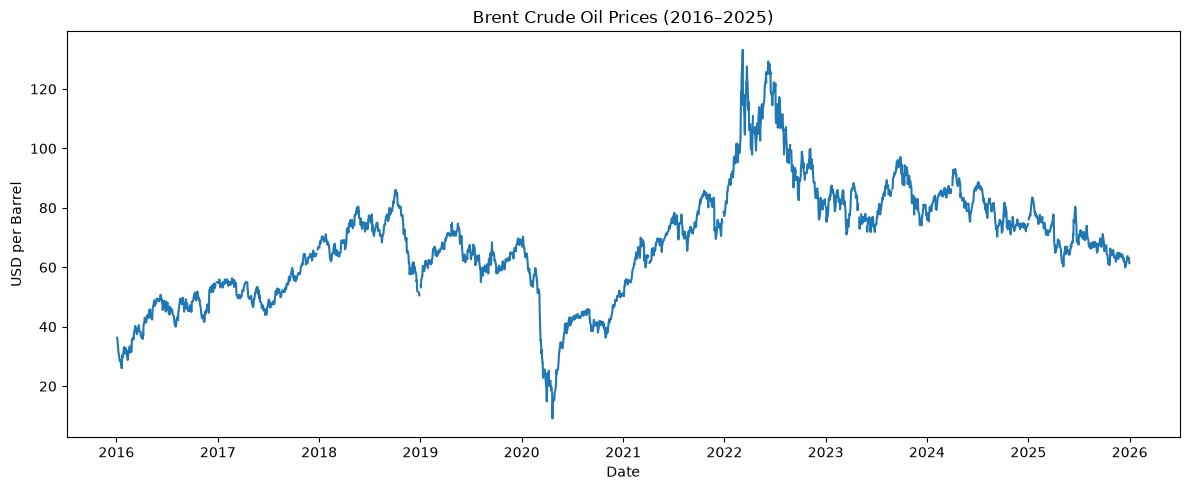

In [ ]:
# Price Graph
plt.figure(figsize=(12, 5))

plt.plot(
    oil["Date"],
    oil["Brent_Price"]
)

plt.title("Brent Crude Oil Prices (2016–2025)")
plt.xlabel("Date")
plt.ylabel("USD per Barrel")

plt.tight_layout()
plt.show()

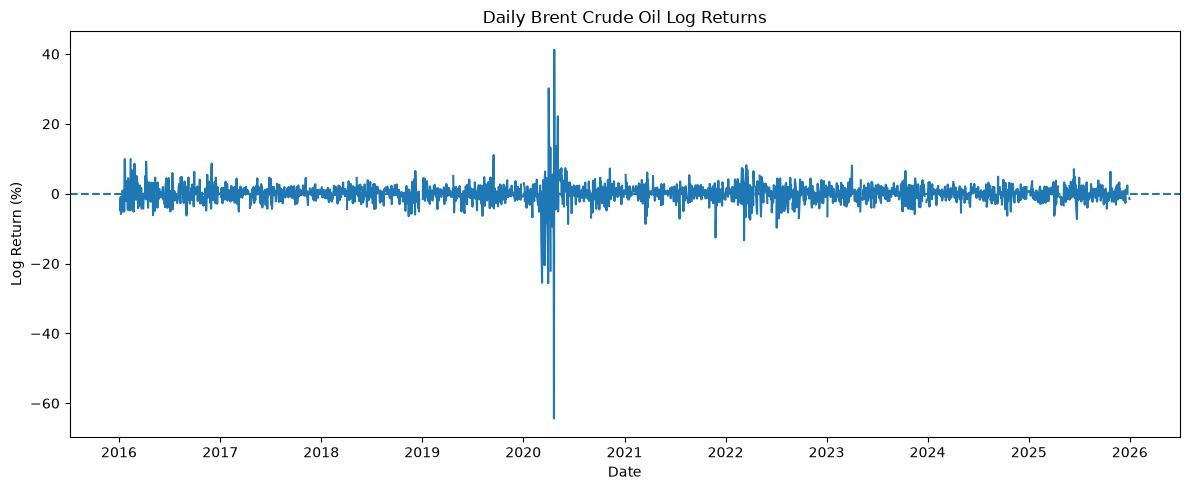

In [33]:
# Returns Graph
plt.figure(figsize=(12, 5))

plt.plot(
    oil["Date"],
    oil["Oil_Return"]
)

plt.axhline(0, linestyle="--")

plt.title("Daily Brent Crude Oil Log Returns")
plt.xlabel("Date")
plt.ylabel("Log Return (%)")

plt.tight_layout()
plt.show()

In [ ]:
# Export Cleaned Data
oil_final = oil[[
    "Date",
    "Brent_Price",
    "Oil_Return",
    "D",
    "Oil_Interaction"
]].copy()

oil_final.to_csv(
    "Brent_cleaned.csv",
    index=False
)

print("Export completed!")
print(oil_final.head())

Export completed!
        Date  Brent_Price  Oil_Return    D  Oil_Interaction
0 2016-01-04        36.28         NaN  NaN              NaN
1 2016-01-05        35.56   -2.004521  0.0             -0.0
2 2016-01-06        33.89   -4.810143  0.0             -0.0
3 2016-01-07        33.57   -0.948717  0.0             -0.0
4 2016-01-08        31.67   -5.826295  0.0             -0.0


The Brent crude oil price series is treated as a daily spot-price benchmark, measured in US dollars per barrel. Daily logarithmic percentage returns are calculated from consecutive recorded prices. The series represents spot-price movements rather than Brent futures closing or settlement prices.